In [4]:
!git clone https://github.com/hanbanthan/landmark-classification
%cd /content/landmark-classification

Cloning into 'landmark-classification'...
remote: Enumerating objects: 55, done.
remote: Counting objects: 100% (55/55), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 55 (delta 24), reused 43 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (55/55), 1.05 MiB | 3.44 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/landmark-classification


In [5]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
%pip install -r requirements.txt

import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 69.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 134.4 MB/s  0:00:00
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 5.0.0.93
    Uninstalling opencv-python-headless-5.0.0.93:
      Successfully uninstalled opencv-python-headless-5.0.0.93
  Attempting uninstall: pytest
    Found existing installation: pytest 8.4.2
    Uninstalling pytest-8.4.2:
      Successfully uninstalled pytest-8.4.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [livelossplot]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
prophet 1.5.0 requires tqdm>=4.63.2, but you have tqdm 4.63.0 which is incompatible.
da

## Setting up

In [7]:
from src.helpers import setup_env

setup_env()

GPU available
done


Computing std: 100%|███████████████████████| 6246/6246 [00:32<00:00, 189.41it/s]


## Data

In [ ]:
!pytest -vv src/data.py -k data_loaders

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 4 items / 1 deselected / 3 selected                                  

src/data.py::test_data_loaders_keys PASSED                               [ 33%]
src/data.py::test_data_loaders_output_type PASSED                        [ 66%]
src/data.py::test_data_loaders_output_shape PASSED                       [100%]

======================= 3 passed, 1 deselected in 3.60s ========================


Question: Describe your chosen procedure for preprocessing the data

- Resizing image to a resolution of 256 pixels, and then cropping it to 224 pixels. (224 is a recommend input size for leveraging Pytorch's pretrained models)
- Using RandAugment to enhance dataset

### Visualize a Batch of Training Data

In [ ]:
!pytest -vv src/data.py -k visualize_one_batch

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 4 items / 3 deselected / 1 selected                                  

src/data.py::test_visualize_one_batch PASSED                             [100%]

======================= 1 passed, 3 deselected in 4.43s ========================


Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])
Reusing cached mean and std


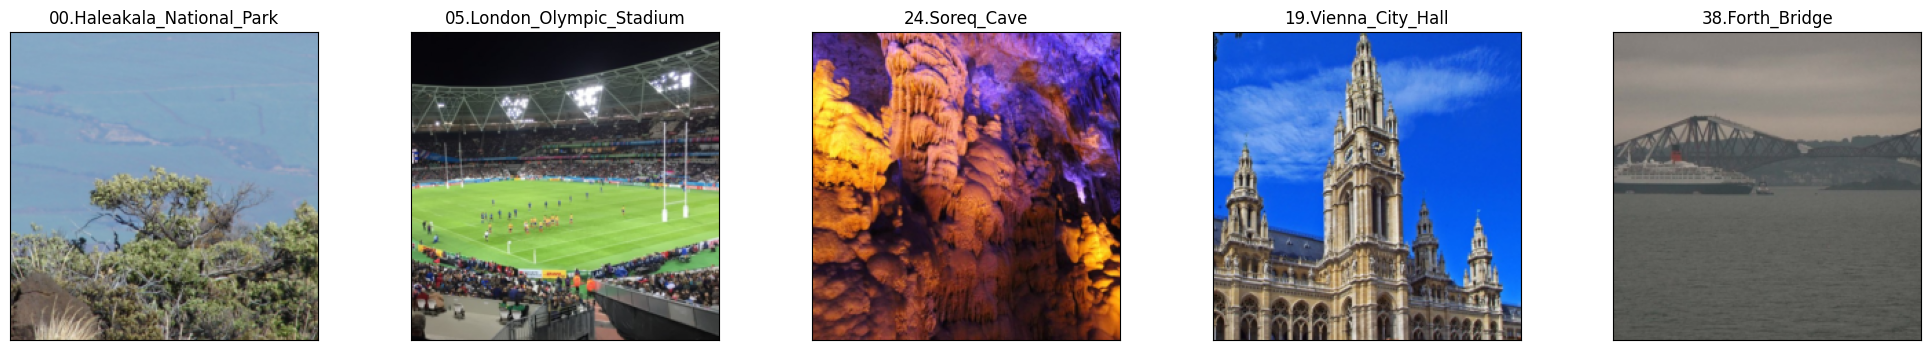

In [ ]:
%matplotlib inline
from src.data import visualize_one_batch, get_data_loaders

data_loaders = get_data_loaders(
    batch_size=5,
    valid_size=0.01,
    num_workers=2,
)

visualize_one_batch(data_loaders)

In [ ]:
## Define model

In [ ]:
!pytest -vv src/model.py

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 1 item                                                               

src/model.py::test_model_construction PASSED                             [100%]

============================== 1 passed in 3.75s ===============================


Question: Outline the steps you took to get the final CNN architecture and your reasoning at each step

Answer:
- I decided to use 5 convolutional layers so that my model could be sufficiently expressive. The last convolution layer is flattened into a fully connected layer head with two hidden layers to best predict image class.      
- I used dropout layers to reduce my model's tendency to overfitting the training data
- I made my model output a 50-dimensional vector to match with the 50 available landmark classes

## Define loss and optimizer

In [ ]:
!pytest -vv src/optimization.py -k get_loss

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 7 items / 6 deselected / 1 selected                                  

src/optimization.py::test_get_loss PASSED                                [100%]

======================= 1 passed, 6 deselected in 2.11s ========================


In [ ]:
!pytest -vv src/optimization.py -k get_optimizer

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 7 items / 1 deselected / 6 selected                                  

src/optimization.py::test_get_optimizer_type PASSED                      [ 16%]
src/optimization.py::test_get_optimizer_is_linked_with_model PASSED      [ 33%]
src/optimization.py::test_get_optimizer_returns_adam PASSED              [ 50%]
src/optimization.py::test_get_optimizer_sets_learning_rate PASSED        [ 66%]
src/optimization.py::test_get_optimizer_sets_momentum PASSED             [ 83%]
src/optimization.py::test_get_optimizer_sets_weight_decat PASSED         [100%]

======================= 6 passed, 1 deselected in 2.93s ========================


## Train and Validate the Model

In [ ]:
!pytest -vv src/train.py -k train_one_epoch

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 4 items / 3 deselected / 1 selected                                  

src/train.py::test_train_one_epoch PASSED                                [100%]

======================= 1 passed, 3 deselected in 8.13s ========================


In [ ]:
!pytest -vv src/train.py -k valid_one_epoch

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 4 items / 3 deselected / 1 selected                                  

src/train.py::test_valid_one_epoch PASSED                                [100%]

======================= 1 passed, 3 deselected in 6.28s ========================


In [ ]:
!pytest -vv src/train.py -k optimize

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 4 items / 3 deselected / 1 selected                                  

src/train.py::test_optimize PASSED                                       [100%]

======================= 1 passed, 3 deselected in 9.21s ========================


In [ ]:
!pytest -vv src/train.py -k one_epoch_test

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 4 items / 3 deselected / 1 selected                                  

src/train.py::test_one_epoch_test PASSED                                 [100%]

======================= 1 passed, 3 deselected in 7.28s ========================


## Putting everything together

In [56]:
batch_size = 64        # size of the minibatch for stochastic gradient descent (or Adam)
valid_size = 0.2       # fraction of the training data to reserve for validation
num_epochs = 60        # number of epochs for training
num_classes = 50       # number of classes. Do not change this
dropout = 0.5         # dropout for our model
learning_rate = 0.005  # Learning rate for SGD (or Adam)
opt = 'sgd'            # optimizer. 'sgd' or 'adam'
weight_decay = 0.01    # regularization. Increase this to combat overfitting

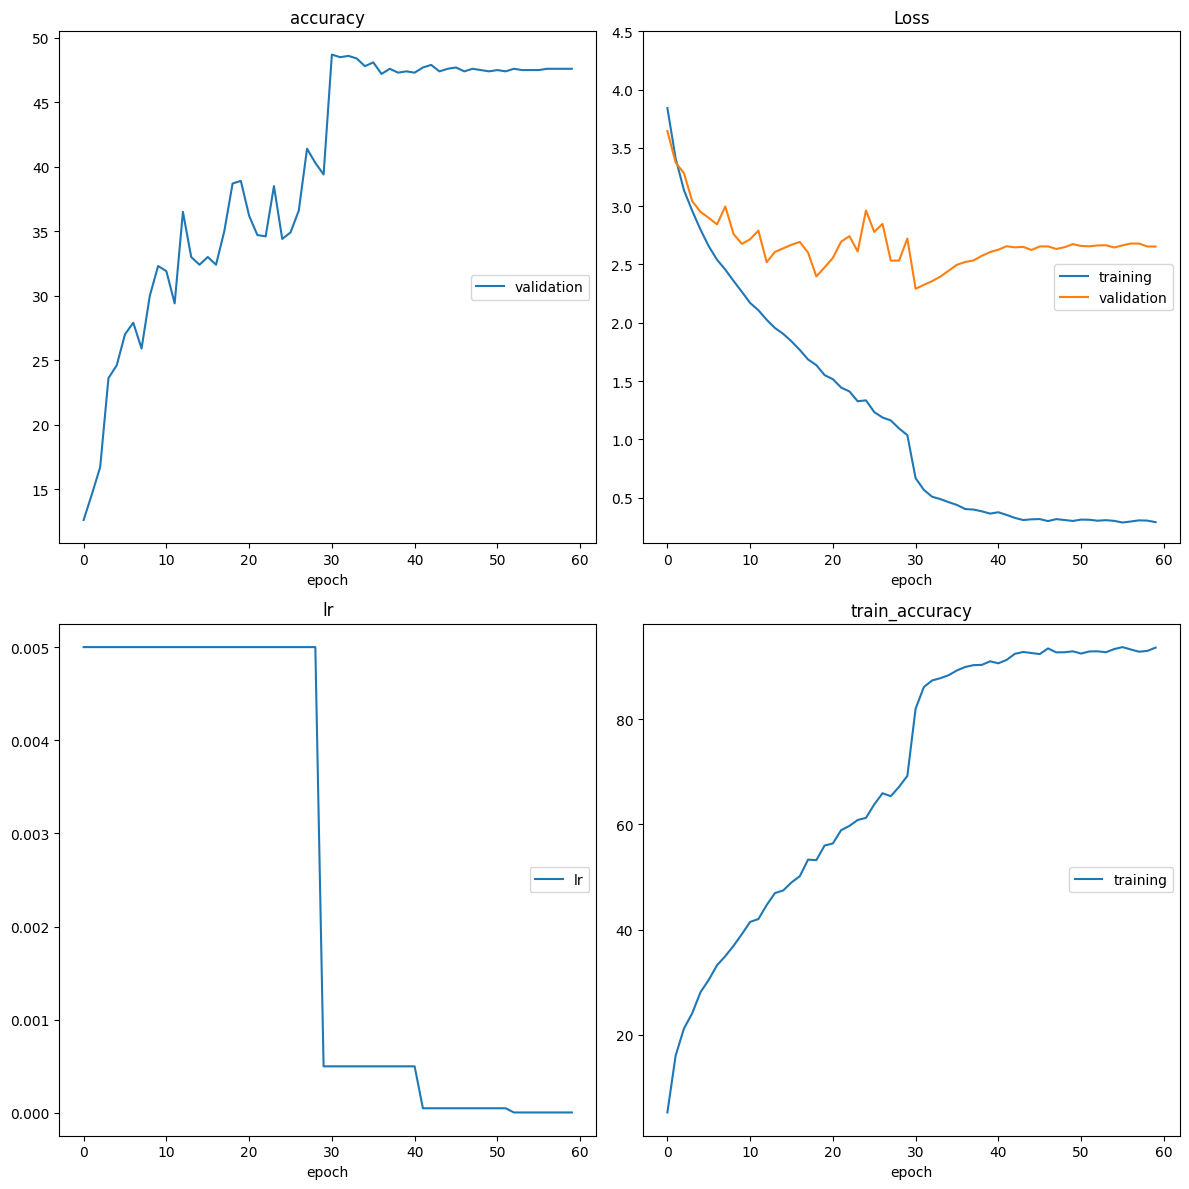

In [57]:
from src.data import get_data_loaders
from src.train import optimize
from src.optimization import get_optimizer, get_loss
from src.model import MyModel

data_loaders = get_data_loaders(
    batch_size=batch_size,
    valid_size=valid_size,
)

model = MyModel(num_classes=num_classes, dropout=dropout)

optimizer = get_optimizer(
    model=model,
    optimizer=opt,
    learning_rate=learning_rate,
    weight_decay=weight_decay
)

loss = get_loss()

optimize(
    data_loaders,
    model,
    optimizer,
    loss,
    n_epochs=num_epochs,
    save_path="checkpoints/best_val_loss.pt",
    interactive_tracking=True,
)

## Testing against the test set

In [59]:
from src.train import one_epoch_test
from src.model import MyModel
import torch

model = MyModel(num_classes=num_classes, dropout=dropout)

checkpoint_path = 'checkpoints/best_val_loss.pt'
model.load_state_dict(torch.load(checkpoint_path))
model.eval()

one_epoch_test(data_loaders["test"], model, loss)

Testing: 100%|██████████████████████████████████| 20/20 [00:02<00:00,  9.36it/s]


Test Loss: 2.113087


Test Accuracy: 51% (640/1250)


2.1130868613719938

## Export using torchscript

In [60]:
!pytest -vv src/predictor.py

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-7.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/landmark-classification
plugins: platformdirs-4.14.3, anyio-4.16.0, langsmith-0.14.17, typeguard-4.6.0
collected 0 items                                                              

============================ no tests ran in 3.41s =============================


In [61]:
from src.predictor import Predictor
from src.helpers import compute_mean_and_std
from src.model import MyModel
from src.data import get_data_loaders
import torch

data_loaders = get_data_loaders(batch_size=1)

class_names = data_loaders["train"].dataset.classes

model = MyModel(num_classes=50, dropout=0.5).cpu()


model.load_state_dict(torch.load("checkpoints/best_val_loss.pt", map_location='cpu'))

mean, std = compute_mean_and_std()
predictor = Predictor(model, class_names, mean, std).cpu()

scripted_predictor = torch.jit.script(predictor)

scripted_predictor.save("checkpoints/original_exported.pt")

Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])
Reusing cached mean and std


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [62]:
import torch

model_reloaded = torch.jit.load("checkpoints/original_exported.pt")

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


In [63]:
from src.predictor import predictor_test
pred, truth = predictor_test(data_loaders["test"], model_reloaded)

100%|███████████████████████████████████████| 1250/1250 [00:20<00:00, 59.92it/s]

Accuracy: 0.512


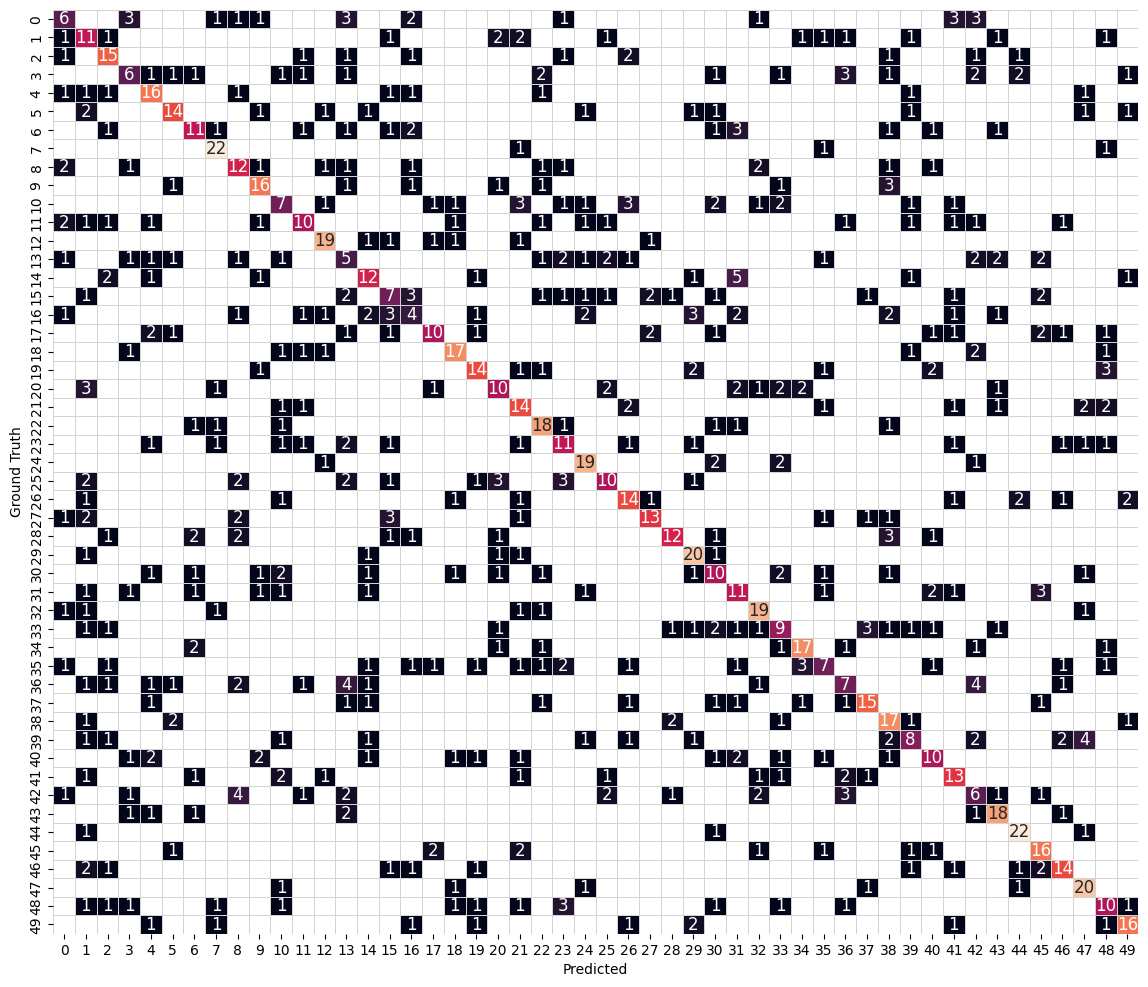

In [64]:
from src.helpers import plot_confusion_matrix

plot_confusion_matrix(pred, truth)